<a href="https://colab.research.google.com/github/KingsleyGranita/DATA-SCIENCE-COURSE-PROJECTS/blob/main/TEXT_MODEL_KING.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [19]:
import pandas as pd
from google.colab import drive
import matplotlib.pyplot as plt

import re
import numpy as np

# GOOGLE DRIVE MOUNT

In [6]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# TEXT EXPLORATION

In [9]:
import os
os.chdir('/content/drive/MyDrive/DATA LAB PROJECT_KING')

In [10]:
text=pd.read_parquet("GenericMixOfTopic.parquet")

In [11]:
text.head(5)

,id,title,topic,topics_with_percentages,text
0,44579372,Julius Julskötare,Mixed,"b'{""Entertainment"":0.67,""Culture"":0.17,""Mass_m...",'Julius Julskötare' (&quot;Julius Christmas ...
1,69360653,Josia Topf,Mixed,"b'{""People"":0.5,""Sports"":0.5,""Academic_discipl...",Infobox athlete | name Josia Topf | fullname...
2,41642068,St. Peter Chaldean Catholic Cathedral (El Cajo...,Mixed,"b'{""Religion"":0.36,""Culture"":0.21,""Time"":0.14,...",St. Peter Cathedral is a Chaldean Catholic C...
3,4351257,Allahabad Address,Mixed,"b'{""History"":0.3,""Government"":0.2,""Philosophy""...","File:Iqbal.jpg|thumb|right| Muhammad Iqbal ,..."
4,648505,Glomerulus (olfaction),Academic_disciplines,"b'{""Academic_disciplines"":1.0,""Business"":0,""Co...",The glomerulus (plural glomeruli) is a spher...


The file contains
- id
- title of the documents
- topic of the document
- topic of the documents with percentage
- text


In [12]:
text.groupby(text['topic']).count()

,id,title,topics_with_percentages,text
topic,,,,
Academic_disciplines,825,825,825,825
Business,825,825,825,825
Communication,288,288,288,288
Concepts,825,825,825,825
Culture,825,825,825,825
Economy,825,825,825,825
Education,825,825,825,825
Energy,825,825,825,825
Engineering,825,825,825,825


-

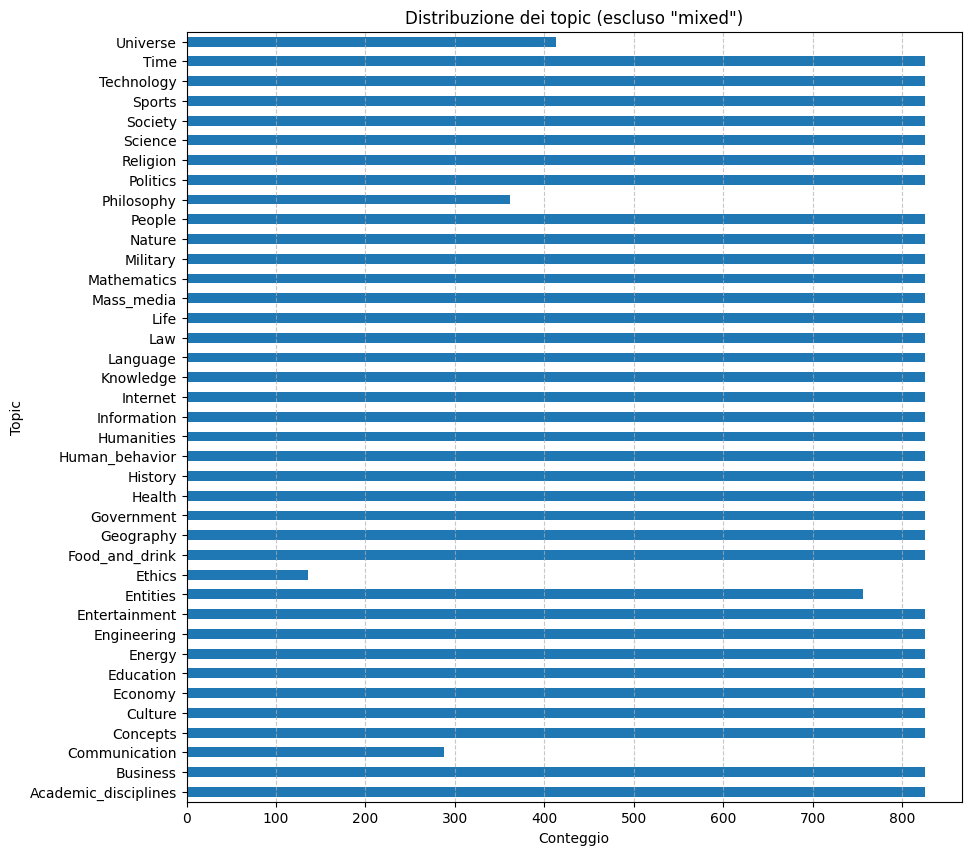

In [18]:
# Escludi il valore 'mixed' dalla colonna 'topic'
filtrato = text[text['topic'] != 'Mixed']

# Raggruppa e conta i valori unici in 'topic'
conteggi = filtrato.groupby('topic').size()
# Istogramma orizzontale
plt.figure(figsize=(10, 10))  # Dimensione più alta per leggibilità
conteggi.plot(kind='barh')
plt.title('Distribuzione dei topic (escluso "mixed")')
plt.xlabel('Conteggio')
plt.ylabel('Topic')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

There seems to be a slight unbalance of certain topics

In [13]:
text['topic'].nunique()

40

there are 40 different topics.

# TEXT REPRESENTATION TF-IDF

TEXT PREPROCESSING
- LEMMATIZATION
- NORMALIZATION
- STOP-WORDS REMOVAL
- TOKENIZATION

In [27]:
pip install nltk

In [33]:
from bs4 import BeautifulSoup
import html
import string
import re
import nltk
from nltk.stem.snowball import SnowballStemmer
from nltk.tokenize import WordPunctTokenizer
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

## TEXT SAMPLE


In [24]:
sample=text['text'].iloc[3]
sample

"  File:Iqbal.jpg|thumb|right| Muhammad Iqbal , then president of the Punjab Muslim League|Muslim League in 1930 and address deliverer The Allahabad Address ( ) was a speech by scholar, Sir Muhammad Iqbal , one of the best-known in History of Pakistan|Pakistani history . It was delivered by Iqbal during the 21st annual session of the All-India Muslim League , on the afternoon of Monday, 29 December 1930, at Allahabad in United Provinces of British India|United Provinces (U. P.). In this address Iqbal outlined a vision of an independent state for the great Muslim-majority provinces in northwestern India, thus becoming the first politician to articulate what would become known as the Two-nation theory —that Muslims are a distinct nation and thus deserve political independence from other regions and communities of India. Allama Iqbal defined the Muslims of India as a nation and suggested that there could be no possibility of peace in the country unless and until they were recognized as a 

the text contains
- links
- File:
- [links]..
- &quot;territorial nationalism&quot; (virgolette)

In [32]:
text['text'].iloc[8]

"  Albanopolis was a city, most likely in Kingdom of Armenia (antiquity)|ancient Armenia , known in Christianity as being the location at which the apostle Bartholomew was crucified. Historical accounts In Butler's Lives of the Saints|Lives of the Saints , 18th-century hagiographer Alban Butler says The popular traditions concerning St Bartholomew are summed up in the Roman Martyrology, which says he &quot;preached the gospel of Christ in India; thence he went into Greater Armenia , and when he had converted many people there to the faith he was flayed alive by the barbarians, and by command of King Astyages fulfilled his martyrdom&quot;. However, Butler himself cautions about taking the geographical clues too literally. He points out that &quot;India&quot; was a name applied indifferently by Greek and Latin writers to Arabia, Ethiopia, Libya, Parthia, Persia and the lands of the Medes. Location Nonetheless, at least three locations have been proposed as possible sites of Albanopolis: 

In [53]:
def preprocess_text(text):
    #Decodifica entità HTML (per risolvere problemi come &quot;)
    text = html.unescape(text)
    soup = BeautifulSoup(text, "html.parser")
    text = soup.get_text(separator=" ")
    #rimozione link
    text = re.sub(r'\[http[^\]]*\]', '', text)
    text = re.sub(r'http\S+', '', text)  # Rimuove link esterni come http://example.com
    text = re.sub(r"www\.[A-Za-z]*\.com", " ", text)
    #rimozione File:...
    text = re.sub(r'File:[^ ]*', '', text)
    #rimozione stop punteggiatura
    text = text.translate(str.maketrans('', '', string.punctuation+ "—"))
    #Sostituisci il simbolo "|" con uno spazio
    text = re.sub(r'\|', ' ', text)
    #CASE FOLDING
    text = text.lower()
    #TOKENIZATION
    tokenizer = WordPunctTokenizer()
    tokens = tokenizer.tokenize(text)
    # rimozione stop-words
    stop_words = set(stopwords.words('english'))
    tokens = [word for word in tokens if word.lower() not in stop_words]
    # Lemmatizzazione
    lemmatizer = WordNetLemmatizer()
    tokens = [lemmatizer.lemmatize(word.lower()) for word in tokens]
    # rimuzione numeri
    tokens = [word for word in tokens if word.isalpha()]
    # final text
    cleaned_text = ' '.join(tokens)

    return cleaned_text,tokens


In [54]:
cleaned_text,tokens=preprocess_text(sample)
cleaned_text

'muhammad iqbal president punjab muslim leaguemuslim league address deliverer allahabad address speech scholar sir muhammad iqbal one bestknown history pakistanpakistani history delivered iqbal annual session allindia muslim league afternoon monday december allahabad united province british indiaunited province u p address iqbal outlined vision independent state great muslimmajority province northwestern india thus becoming first politician articulate would become known twonation theory muslim distinct nation thus deserve political independence region community india allama iqbal defined muslim india nation suggested could possibility peace country unless recognized nation federal system muslim majority unit given privilege given hindu majority unit way muslim hindu could prosper accordance respective cultural value speech emphasized unlike christianity islam came legal concept civic significance religious ideal considered inseparable social order therefore construction policy national

In [55]:
tokens

['muhammad',
 'iqbal',
 'president',
 'punjab',
 'muslim',
 'leaguemuslim',
 'league',
 'address',
 'deliverer',
 'allahabad',
 'address',
 'speech',
 'scholar',
 'sir',
 'muhammad',
 'iqbal',
 'one',
 'bestknown',
 'history',
 'pakistanpakistani',
 'history',
 'delivered',
 'iqbal',
 'annual',
 'session',
 'allindia',
 'muslim',
 'league',
 'afternoon',
 'monday',
 'december',
 'allahabad',
 'united',
 'province',
 'british',
 'indiaunited',
 'province',
 'u',
 'p',
 'address',
 'iqbal',
 'outlined',
 'vision',
 'independent',
 'state',
 'great',
 'muslimmajority',
 'province',
 'northwestern',
 'india',
 'thus',
 'becoming',
 'first',
 'politician',
 'articulate',
 'would',
 'become',
 'known',
 'twonation',
 'theory',
 'muslim',
 'distinct',
 'nation',
 'thus',
 'deserve',
 'political',
 'independence',
 'region',
 'community',
 'india',
 'allama',
 'iqbal',
 'defined',
 'muslim',
 'india',
 'nation',
 'suggested',
 'could',
 'possibility',
 'peace',
 'country',
 'unless',
 'recogni

I'M GOING TO USE THE TF-IDF WEIGHTING TO HELP THE LSA TO FOCUS ON MEANINGFUL SEMANTHIC PATTERNS

In [ ]:
vectorizer = TfidfVectorizer()
docs_tfidf = vectorizer.fit_transform(data.preprocessed)

# LATENT SEMANTIC ANALYSIS